In [1]:
"""
Preprocesamiento_limpieza.py — Limpieza y preprocesamiento del Dow Jones (Reto 9)

Dataset de entrada: Datos/DowJones/*.csv (26 ficheros, uno por accion, formato marketstack)
Dataset de salida:  Datos/dowjones_limpio.csv

Objetivo: dejar un dataset unico, limpio, con frecuencia homogenea y sin missings,
que sirva de entrada para la seleccion de la cartera (Seccion 3 de la descripcion tecnica).

Pasos (siguiendo el procedimiento visto en clase - Procesamiento de Series Temporales):
    1. Carga y unificacion
    2. Duplicados y orden temporal
    3. Comprobacion de calidad / coherencia OHLC
    4. Homogenizacion de la frecuencia muestral
    5. Diagnostico de missings y ajuste por splits
    6. Completado con Yahoo Finance
    7. Interpolacion final, control de duplicados y coherencia
    8. Analisis descriptivo
    9. Guardado del dataset limpio

NOTA: el paso 6 necesita conexion a internet (Yahoo Finance).
"""

import os
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator, FuncFormatter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

pd.set_option("display.max_columns", None)


## 1. Carga Y Unificacion De Los Datos

In [2]:
# Se leen los 26 ficheros csv (uno por accion) y se unen en un unico DataFrame.
# Las fechas se convierten a datetime con zona horaria UTC.

# Ruta relativa dentro del repositorio (ajustar si la estructura de carpetas es otra)
RUTA_DATOS = os.path.join("Datos", "DowJones")

lista_df = []
for nombre_archivo in os.listdir(RUTA_DATOS):
    if nombre_archivo.endswith(".csv"):
        temp = pd.read_csv(os.path.join(RUTA_DATOS, nombre_archivo))
        lista_df.append(temp)

df = pd.concat(lista_df, ignore_index=True)
df["date"] = pd.to_datetime(df["date"], utc=True)

print(f"Archivos leidos: {len(lista_df)}")
print(f"Filas totales:   {len(df)}")
print(f"Simbolos:        {df['symbol'].nunique()}")
print(df.dtypes)


Archivos leidos: 26
Filas totales:   2744418
Simbolos:        26
open                    float64
high                    float64
low                     float64
last                    float64
close                   float64
volume                  float64
date        datetime64[us, UTC]
symbol                      str
exchange                    str
dtype: object


## 2. Duplicados Y Orden Temporal

In [3]:
# Puede haber registros repetidos (mismo simbolo + misma fecha) si algun fichero
# se solapa. Los eliminamos y ordenamos la serie cronologicamente por simbolo,
# que es el orden que necesitaremos para interpolar y para el resampling posterior.

df = df.drop_duplicates(subset=["symbol", "date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)
print("Filas tras quitar duplicados:", len(df))


Filas tras quitar duplicados: 2744418


## 3. Comprobacion De Calidad / Coherencia Ohlc

In [4]:
# Antes de imputar nada, comprobamos que los precios sean financieramente
# coherentes: `high` no puede ser menor que `low`, y ningun precio puede ser
# negativo o cero. Las filas incoherentes se marcan como missing (NaN) para que
# el tratamiento de missings las repare, en vez de dejarlas colar como validas.

cond_incoherente = (
    (df["high"] < df["low"])
    | (df["open"] <= 0) | (df["high"] <= 0) | (df["low"] <= 0)
    | (df["close"] <= 0)
)
print("Filas con incoherencias OHLC:", cond_incoherente.sum())

cols_precio = ["open", "high", "low", "close", "last"]
df.loc[cond_incoherente, cols_precio] = np.nan


Filas con incoherencias OHLC: 0


## 4. Homogenizacion De La Frecuencia Muestral

In [5]:
# Los datos vienen a frecuencia INTRADIA e irregular (mayoritariamente cada 5
# minutos, pero con huecos de tamano variable). Ademas, no todas las acciones
# cubren el mismo periodo: 6 de las 26 empiezan en 2018 y las 20 restantes solo
# tienen datos desde el 29/05/2020.
#
# Para trabajar con las series (cartera, volatilidad, Montecarlo) se necesita una
# frecuencia homogenea: se agrega a FRECUENCIA DIARIA (dias habiles), construyendo
# un OHLCV estandar por dia y simbolo:
#   - open   = primer valor del dia
#   - high   = maximo del dia
#   - low    = minimo del dia
#   - close  = ultimo precio del dia (columna `last` de marketstack)
#   - volume = volumen total del dia (solo disponible en la fila resumen, ver abajo)
#
# Particularidades del formato marketstack que se tienen en cuenta:
#   * La columna `close` de las filas intradia NO es el cierre de ese dia, sino el
#     cierre del dia ANTERIOR. El precio real del dia esta en `last`.
#     En el tramo 2018-2020 (datos diarios) `last` esta vacio y `close` si es el
#     dato diario, por lo que se usa `close` unicamente en ese tramo.
#   * Las filas de medianoche (00:00 UTC) contienen el resumen del dia ANTERIOR.
#     Se desplazan 3 horas hacia atras para que caigan en su dia correcto.
#   * El volumen intradia es ACUMULADO y solo recoge la bolsa IEX (una pequena
#     fraccion del total). El volumen completo del dia esta unicamente en la fila
#     resumen de medianoche; los dias sin fila resumen quedan como missing y se
#     completan con Yahoo Finance en el paso 6 (no se suma, para no inflarlo).


def resample_symbol(g):
    g = g.set_index("date").sort_index()

    # Volumen: solo se toma de las filas resumen de medianoche (00:00 UTC), que
    # contienen el volumen total del dia (se marcan ANTES de desplazar las horas).
    es_resumen = (g.index.hour == 0) & (g.index.minute == 0)
    volumen_resumen = g["volume"].where(es_resumen)

    # Las filas de medianoche resumen el dia anterior: se desplazan 3h para
    # asignarlas al dia al que realmente pertenecen.
    g.index = g.index - pd.Timedelta(hours=3)
    volumen_resumen.index = g.index

    # Precio de cierre diario: `last`; en el tramo inicial sin `last`, `close`.
    primer_last = g["last"].first_valid_index()
    precio = g["last"].copy()
    antes = g.index < primer_last if primer_last is not None else np.ones(len(g), bool)
    precio[antes] = g.loc[antes, "close"]
    cierre = precio.resample("B").last()

    return pd.DataFrame({
        "open":   g["open"].resample("B").first(),
        "high":   g["high"].resample("B").max(),
        "low":    g["low"].resample("B").min(),
        "last":   cierre,
        "close":  cierre,
        "volume": volumen_resumen.resample("B").max(),
    })


daily_list = []
for symbol, g in df.groupby("symbol"):
    d = resample_symbol(g)
    d["symbol"] = symbol
    d["exchange"] = g["exchange"].iloc[0]
    daily_list.append(d)

df_daily = pd.concat(daily_list).reset_index()
print("Filas tras homogenizar a frecuencia diaria:", len(df_daily))
print(df_daily.groupby("symbol")["date"].agg(["min", "max", "count"]))


Filas tras homogenizar a frecuencia diaria: 10469
                             min                       max  count
symbol                                                           
AAPL   2018-06-06 00:00:00+00:00 2021-06-30 00:00:00+00:00    801
AMGN   2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
AXP    2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
BA     2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
CAT    2018-06-11 00:00:00+00:00 2021-06-30 00:00:00+00:00    798
CRM    2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
CSCO   2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
CVX    2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
DIS    2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
DOW    2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
GS     2018-06-11 00:00:00+00:00 2021-06-30 00:00:00+00:00    798
HD     2020-05-29 00:00:00+00:00 2021-06-30 00:00:00+00:00    284
IBM    2020-05-29 00:00:00

## 5. Diagnostico De Missings Y Ajuste Por Splits

In [6]:
# Tras el resampling a dias habiles aparecen valores faltantes. Primero se
# completan con Yahoo Finance (paso 6) y, si aun quedan huecos, se interpolan
# linealmente por simbolo como ultimo recurso (paso 7).

print("Missings antes de completar con Yahoo Finance:")
print(df_daily[["open", "high", "low", "last", "close", "volume"]].isna().sum())

# Ajuste por splits. Los precios de marketstack NO estan ajustados por splits
# (p. ej. AAPL pasa de ~500 a ~125 el 31/08/2020 por el split 4:1), mientras que
# los de Yahoo Finance si. Antes de mezclar ambas fuentes hay que poner los datos
# propios en la misma escala: se dividen los precios ANTERIORES al dia del split
# entre el ratio, y se multiplica el volumen anterior por el ratio.


def ajustar_splits(df, columna_precio_list=["open", "high", "low", "last", "close"]):
    """Ajusta retroactivamente los precios anteriores a cada split, para que
    toda la serie quede en la misma escala que usa Yahoo Finance (post-split).
    Por cada simbolo y cada split detectado, divide los precios ANTERIORES
    a la fecha del split entre el ratio del split, y multiplica el volumen
    ANTERIOR por el ratio."""

    df = df.copy()

    # Asegurar formato datetime y limpiar zonas horarias
    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None)

    fecha_ini = df["date"].min()
    fecha_fin = df["date"].max()

    for simbolo in sorted(df["symbol"].unique()):
        ticker = yf.Ticker(simbolo)
        splits = ticker.splits

        if splits.empty:
            continue

        # Normalizar zona horaria de los splits de yfinance
        splits.index = splits.index.tz_localize(None)
        splits = splits[(splits.index >= fecha_ini) & (splits.index <= fecha_fin)]

        for fecha_split, ratio in splits.items():
            # Filas de la misma empresa ESTRICTAMENTE anteriores al dia del split
            # (se normaliza la fecha para no ajustar la fila del propio dia del split)
            mask = (df["symbol"] == simbolo) & (df["date"] < pd.Timestamp(fecha_split).normalize())

            if mask.sum() == 0:
                continue

            print(f"{simbolo}: ajustando {mask.sum()} filas anteriores a "
                  f"{fecha_split.date()} (ratio {ratio})")

            for col in columna_precio_list:
                if col in df.columns:
                    df.loc[mask, col] = df.loc[mask, col] / ratio

            if "volume" in df.columns:
                df.loc[mask, "volume"] = df.loc[mask, "volume"] * ratio

    return df

df_daily_apple_original = df_daily[df_daily["symbol"] == "AAPL"].copy()
df_daily = ajustar_splits(df_daily)



Missings antes de completar con Yahoo Finance:
open       292
high       292
low        292
last       475
close      475
volume    7871
dtype: int64
AAPL: ajustando 583 filas anteriores a 2020-08-31 (ratio 4.0)
MRK: ajustando 264 filas anteriores a 2021-06-03 (ratio 1.048)


## 6. Completado Con Datos De Yahoo Finance

In [7]:
# El conjunto facilitado contiene datos de 26 empresas. Para completar la
# informacion se utiliza Yahoo Finance:
#   - Se descargan las 30 empresas del Dow Jones.
#   - Las 4 empresas que no venian en el conjunto original se anaden enteras.
#   - En las empresas originales, Yahoo Finance SOLO se usa para rellenar valores
#     ausentes (prioridad al dato original), sin crear filas duplicadas.

# 6.1 Definicion de los 30 tickers del Dow Jones
TICKERS_DOW30 = sorted(
    [
        "AAPL", "AMGN", "AMZN", "AXP", "BA", "CAT", "CRM", "CSCO",
        "CVX", "DIS", "GS", "HD", "HON", "IBM", "JNJ", "JPM",
        "KO", "MCD", "MMM", "MRK", "MSFT", "NKE", "NVDA", "PG",
        "SHW", "TRV", "UNH", "V", "VZ", "WMT",
    ]
)

# Filtrar primero el dataset para conservar unicamente las 30 del Dow 30
df_daily = df_daily[df_daily["symbol"].isin(TICKERS_DOW30)].copy()

if "exchange" in df_daily.columns:
    df_daily = df_daily.drop(columns=["exchange"])

df_daily["date"] = pd.to_datetime(df_daily["date"], utc=True)

# Fecha de inicio tomada del dataset previo; fecha fin fija (yf.download excluye el 'end')
fecha_ini = df_daily["date"].min().strftime("%Y-%m-%d")
fecha_fin = "2026-01-01"

# 6.2 Descarga en un solo lote desde Yahoo Finance
print(f"Descargando datos desde {fecha_ini} hasta 2025-12-31...")
df_raw = yf.download(
    tickers=TICKERS_DOW30,
    start=fecha_ini,
    end=fecha_fin,
    progress=True,
    auto_adjust=False,
    group_by="ticker",
)

# 6.3 Procesado de los datos descargados
datos_yahoo = {}

for simbolo in TICKERS_DOW30:
    try:
        if len(TICKERS_DOW30) > 1 and simbolo in df_raw.columns.levels[0]:
            hist = df_raw[simbolo].copy()
        elif simbolo in df_raw.columns:
            hist = df_raw.copy()
        else:
            continue

        hist = hist.dropna(how="all")
        if hist.empty:
            continue

        hist = hist.reset_index()
        hist.columns = [str(col).lower().replace(" ", "_") for col in hist.columns]

        rename_dict = {
            "date": "date",
            "open": "open",
            "high": "high",
            "low": "low",
            "close": "close",
            "adj_close": "adj_close",
            "adj close": "adj_close",
            "volume": "volume",
        }
        hist = hist.rename(columns=rename_dict)

        if "adj_close" not in hist.columns:
            hist["adj_close"] = hist["close"]
        if "last" not in hist.columns:
            hist["last"] = hist["close"]

        hist["symbol"] = simbolo
        hist["date"] = pd.to_datetime(hist["date"], utc=True)

        datos_yahoo[simbolo] = hist

    except Exception as e:
        print(f"Error procesando {simbolo}: {e}")


# 6.4 Alineacion de escala con Yahoo Finance
# Yahoo Finance tambien ajusta las escisiones (spin-offs) de las empresas
# (p. ej. Solventum en MMM), que marketstack no refleja. Para no mezclar dos
# escalas en una misma serie, se calcula el factor mediano Yahoo/original sobre
# los dias comunes y, si difiere de 1, se reescalan los precios originales.


def alinear_escala_con_yahoo(df_orig, df_yh, umbral=0.005):
    cols = ["open", "high", "low", "last", "close"]
    o = df_orig.set_index("date")
    y = df_yh.set_index("date")
    comunes = o.index.intersection(y.index)
    ratio = (y.loc[comunes, "close"] / o.loc[comunes, "close"]).replace([np.inf, -np.inf], np.nan).dropna()
    if ratio.empty:
        return df_orig, 1.0
    f = ratio.median()
    if abs(f - 1) > umbral:
        df_orig = df_orig.copy()
        df_orig[cols] = df_orig[cols] * f
    return df_orig, f


# 6.5 Fusion: se conservan los datos originales y se completa con Yahoo donde falte
dfs_actualizados = []
simbolos_existentes = set(df_daily["symbol"].unique())

for simbolo in TICKERS_DOW30:
    if simbolo not in datos_yahoo:
        continue

    df_yh = datos_yahoo[simbolo].copy()

    if simbolo in simbolos_existentes:
        df_orig = df_daily[df_daily["symbol"] == simbolo].copy()
        df_orig, f = alinear_escala_con_yahoo(df_orig, df_yh)
        if abs(f - 1) > 0.005:
            print(f"{simbolo}: escala de marketstack reescalada x{f:.4f} para igualar a Yahoo")

        # 1. Unir los calendarios de fechas de ambos datasets (Outer Merge)
        merged = pd.merge(
            df_yh, df_orig, on=["date", "symbol"], how="outer", suffixes=("_yh", "_orig")
        )

        # 2. Rellenar las columnas: prioridad al dato original (_orig);
        #    si el dato original es NaN, se toma el dato de Yahoo (_yh)
        cols_evaluar = ["open", "high", "low", "last", "close", "adj_close", "volume"]

        for col in cols_evaluar:
            col_orig = f"{col}_orig"
            col_yh = f"{col}_yh"

            if col_orig in merged.columns and col_yh in merged.columns:
                merged[col] = merged[col_orig].fillna(merged[col_yh])
            elif col_orig in merged.columns:
                merged[col] = merged[col_orig]
            elif col_yh in merged.columns:
                merged[col] = merged[col_yh]

        # 3. Limpiar columnas auxiliares
        cols_a_borrar = [c for c in merged.columns if c.endswith("_orig") or c.endswith("_yh")]
        merged = merged.drop(columns=cols_a_borrar)

        dfs_actualizados.append(merged)
    else:
        dfs_actualizados.append(df_yh)

# Reconstruir el DataFrame unificado
df_daily = pd.concat(dfs_actualizados, ignore_index=True)

# Filtrado final de fechas y eliminacion de duplicados
df_daily = df_daily[df_daily["date"] <= pd.Timestamp("2025-12-31", tz="UTC")]
df_daily = df_daily.drop_duplicates(subset=["symbol", "date"], keep="first")
df_daily = df_daily.sort_values(["symbol", "date"]).reset_index(drop=True)

# Comprobacion: si Yahoo falla al descargar algun simbolo el proceso se detiene
# aqui, en vez de guardar un csv incompleto.
faltan = set(TICKERS_DOW30) - set(df_daily["symbol"].unique())
assert not faltan, f"Faltan simbolos: {faltan}. Vuelve a ejecutar esta celda."

# 6.6 Diagnostico final
print("\n" + "=" * 40)
print("PROCESO COMPLETADO EXITOSAMENTE")
print("=" * 40)
print(f"Total de filas finales: {len(df_daily)}")
print(f"Numero de empresas: {df_daily['symbol'].nunique()}")
print(f"Empresas faltantes del Dow 30: {set(TICKERS_DOW30) - set(df_daily['symbol'].unique())}")
print(f"Columnas finales: {df_daily.columns.tolist()}")

# Resumen de valores nulos por columna
print("--- Cantidad de nulos por columna ---")
print(df_daily.isna().sum())

# Filas que tienen al menos un valor nulo
filas_con_nulos = df_daily[df_daily.isna().any(axis=1)]
print(f"\nTotal de filas con algun valor nulo: {len(filas_con_nulos)}")
print(filas_con_nulos.head())

# Eliminar la columna 'exchange' si existe en el DataFrame
if "exchange" in df_daily.columns:
    df_daily = df_daily.drop(columns=["exchange"])

print("Columnas resultantes tras eliminar 'exchange':")
print(df_daily.columns.tolist())


Descargando datos desde 2018-06-06 hasta 2025-12-31...


[*********************100%***********************]  30 of 30 completed


IBM: escala de marketstack reescalada x0.9560 para igualar a Yahoo
MMM: escala de marketstack reescalada x0.8361 para igualar a Yahoo

PROCESO COMPLETADO EXITOSAMENTE
Total de filas finales: 57431
Numero de empresas: 30
Empresas faltantes del Dow 30: set()
Columnas finales: ['date', 'adj_close', 'symbol', 'open', 'high', 'low', 'last', 'close', 'volume']
--- Cantidad de nulos por columna ---
date           0
adj_close    311
symbol         0
open         216
high         216
low          216
last         216
close        216
volume       311
dtype: int64

Total de filas con algun valor nulo: 311
                         date  adj_close symbol     open     high      low  \
20  2018-07-04 00:00:00+00:00        NaN   AAPL  45.9100  45.9100  45.9100   
63  2018-09-03 00:00:00+00:00        NaN   AAPL  56.9075  56.9075  56.9075   
121 2018-11-22 00:00:00+00:00        NaN   AAPL  44.1900  44.1900  44.1900   
130 2018-12-05 00:00:00+00:00        NaN   AAPL  44.1725  44.1725  44.1725   
144 201

## 7. Interpolacion Final, Control De Duplicados Y Coherencia

In [8]:
# Los valores que todavia falten despues de Yahoo Finance se completan mediante
# interpolacion lineal dentro de cada simbolo. Despues se comprueba que exista
# una unica observacion por `symbol + date`, se recalcula el numero de dias entre
# observaciones y se vuelve a comprobar la coherencia OHLC.

# -----------------------------------------------------------------------------
# 7.0 Eliminacion de festivos (dias sin sesion de bolsa)
# -----------------------------------------------------------------------------
# Un festivo bursatil no tiene sesion, asi que no debe conservarse ni interpolarse.
# Se detectan por los datos, sin calendario externo, con dos condiciones:
#   - dia sin ningun dato de precio (todas las columnas vacias), o
#   - fila "plana" (open = high = low = close) que solo repite el cierre del dia
#     anterior, que es como aparecen los festivos en el tramo 2018-2020.
# Se ejecuta DESPUES de completar con Yahoo para no borrar dias reales que falten
# en marketstack pero que Yahoo si tiene.

df_daily = df_daily.sort_values(["symbol", "date"]).reset_index(drop=True)
columnas_precio = ["open", "high", "low", "last", "close"]

sin_datos = df_daily[columnas_precio].isna().all(axis=1)
plano_repetido = (
    (df_daily["open"] == df_daily["high"])
    & (df_daily["high"] == df_daily["low"])
    & (df_daily["low"] == df_daily["close"])
    & (df_daily["close"] == df_daily.groupby("symbol")["close"].shift(1))
)

filas_antes = len(df_daily)
df_daily = df_daily[~(sin_datos | plano_repetido)].copy()
print(f"Filas eliminadas por ser festivo/sin sesion: {filas_antes - len(df_daily)}")

# -----------------------------------------------------------------------------
# 7.1 Interpolacion final
# -----------------------------------------------------------------------------

columnas_precio = ["open", "high", "low", "last", "close"]

for columna in columnas_precio:
    df_daily[columna] = (
        df_daily.groupby("symbol")[columna]
        .transform(lambda x: x.interpolate(method="linear"))
    )

# Si quedara algun NaN al principio o al final de una serie,
# se utiliza el ultimo/primer valor disponible como respaldo.
for columna in columnas_precio:
    df_daily[columna] = (
        df_daily.groupby("symbol")[columna]
        .transform(lambda x: x.ffill().bfill())
    )

# El volumen que siga faltando se considera 0.
df_daily["volume"] = df_daily["volume"].fillna(0)

print("Valores faltantes despues de la imputacion final:")
print(df_daily[["open", "high", "low", "last", "close", "volume"]].isna().sum())

# -----------------------------------------------------------------------------
# 7.2 Control de duplicados
# -----------------------------------------------------------------------------

duplicados = df_daily.duplicated(subset=["symbol", "date"]).sum()
print("\nDuplicados simbolo-fecha:", duplicados)

# -----------------------------------------------------------------------------
# 7.3 Dias entre observaciones
# -----------------------------------------------------------------------------

df_daily = df_daily.sort_values(["symbol", "date"]).reset_index(drop=True)

df_daily["dias_entre_observaciones"] = (
    df_daily.groupby("symbol")["date"].diff().dt.days
)

df_daily["dias_entre_observaciones"] = (
    df_daily["dias_entre_observaciones"].fillna(0)
)

print("Valores faltantes en dias_entre_observaciones:",
      df_daily["dias_entre_observaciones"].isna().sum())

# -----------------------------------------------------------------------------
# 7.4 Comprobacion OHLC final
# -----------------------------------------------------------------------------

cond_incoherente = (
    (df_daily["high"] < df_daily["low"])
    | (df_daily["open"] <= 0)
    | (df_daily["high"] <= 0)
    | (df_daily["low"] <= 0)
    | (df_daily["close"] <= 0)
)

print("Filas con incoherencias OHLC finales:", cond_incoherente.sum())


Filas eliminadas por ser festivo/sin sesion: 311
Valores faltantes despues de la imputacion final:
open      0
high      0
low       0
last      0
close     0
volume    0
dtype: int64

Duplicados simbolo-fecha: 0
Valores faltantes en dias_entre_observaciones: 0
Filas con incoherencias OHLC finales: 0


## 8. Analisis Descriptivo para comprobar que la limpieza se ha realizado correctamente

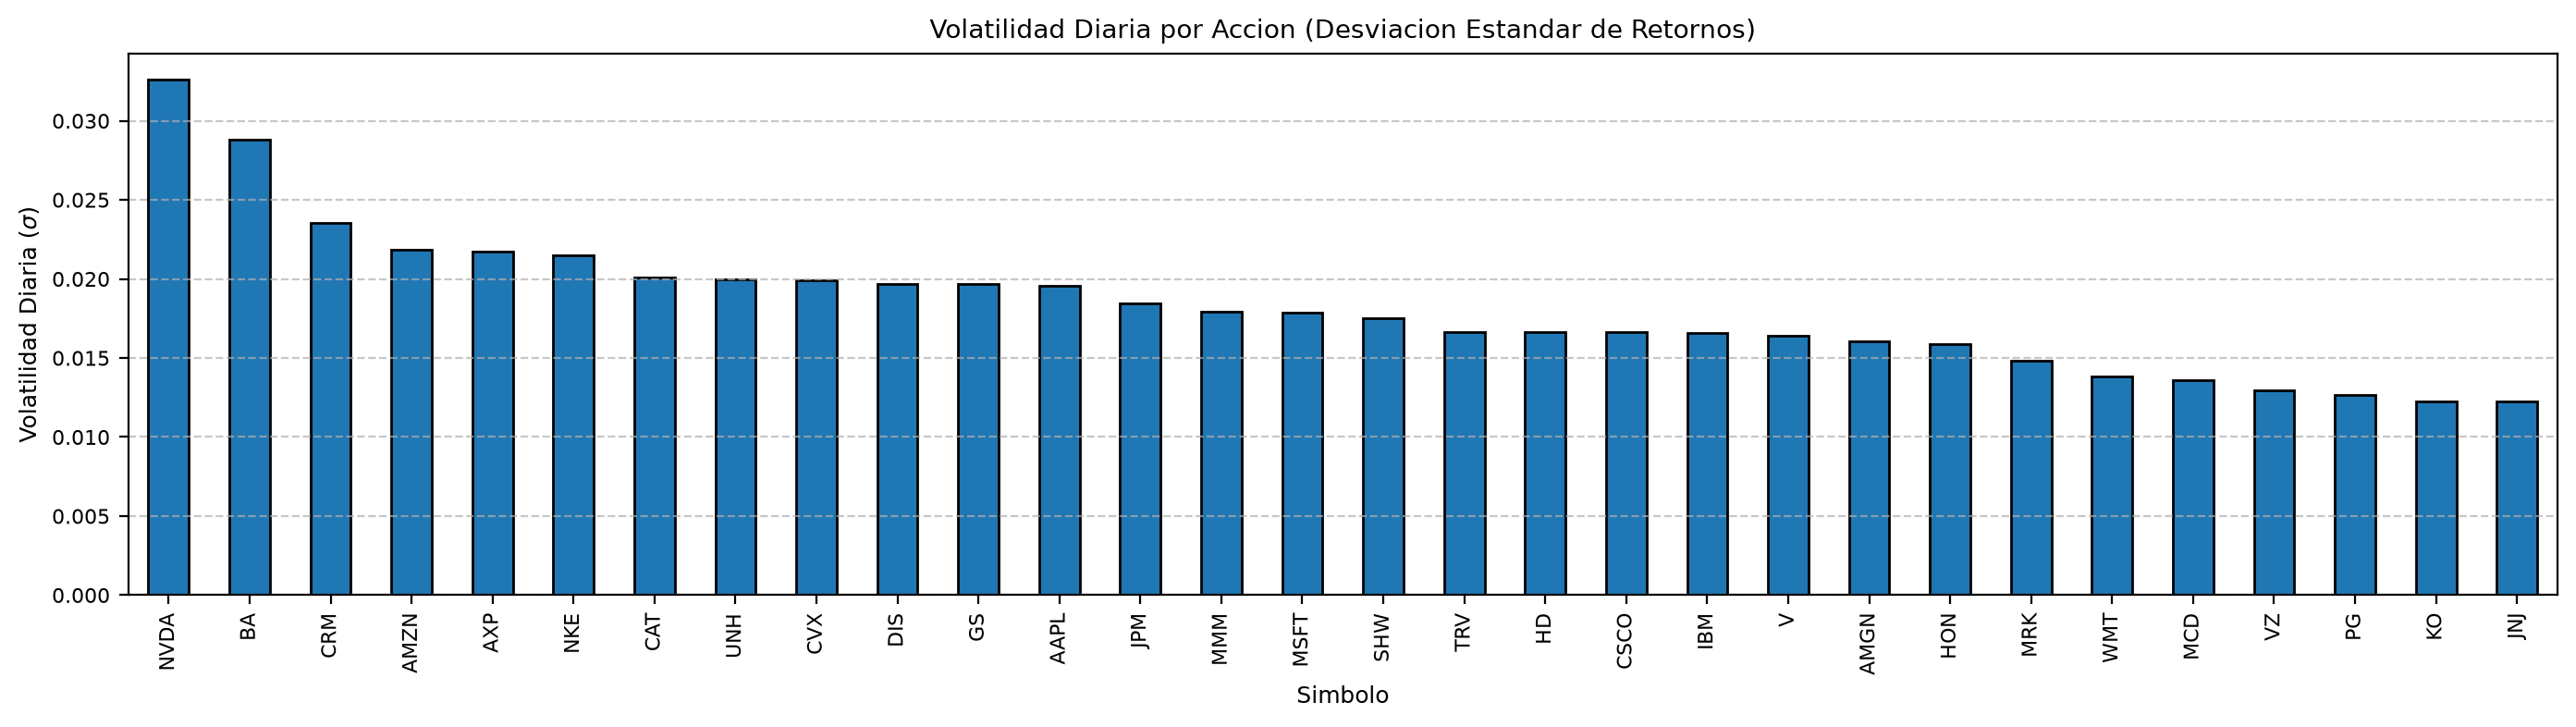

         count        mean         std         min         25%         50%  \
symbol                                                                       
AAPL    1904.0  142.981033   64.197975   35.521250   79.445000  148.700005   
AMGN    1904.0  246.287490   40.954065  166.699997  218.864994  241.495003   
AMZN    1904.0  144.024867   45.500918   67.197998   97.511497  147.419998   
AXP     1904.0  174.040339   71.948901   68.959999  118.390001  157.070000   
BA      1904.0  229.957340   75.229521   95.010002  177.029995  209.040001   
CAT     1904.0  235.697613  105.991774   91.870000  142.730000  212.574997   
CRM     1904.0  213.560016   54.607928  120.669998  160.489994  212.069999   
CSCO    1904.0   51.396870    7.963400   33.200001   45.987501   49.610001   
CVX     1904.0  132.475693   28.112908   54.220001  112.735003  136.689995   
DIS     1904.0  120.977794   27.828542   79.320000  100.584999  112.945000   
GS      1904.0  359.772090  162.027575  134.965000  222.947500  

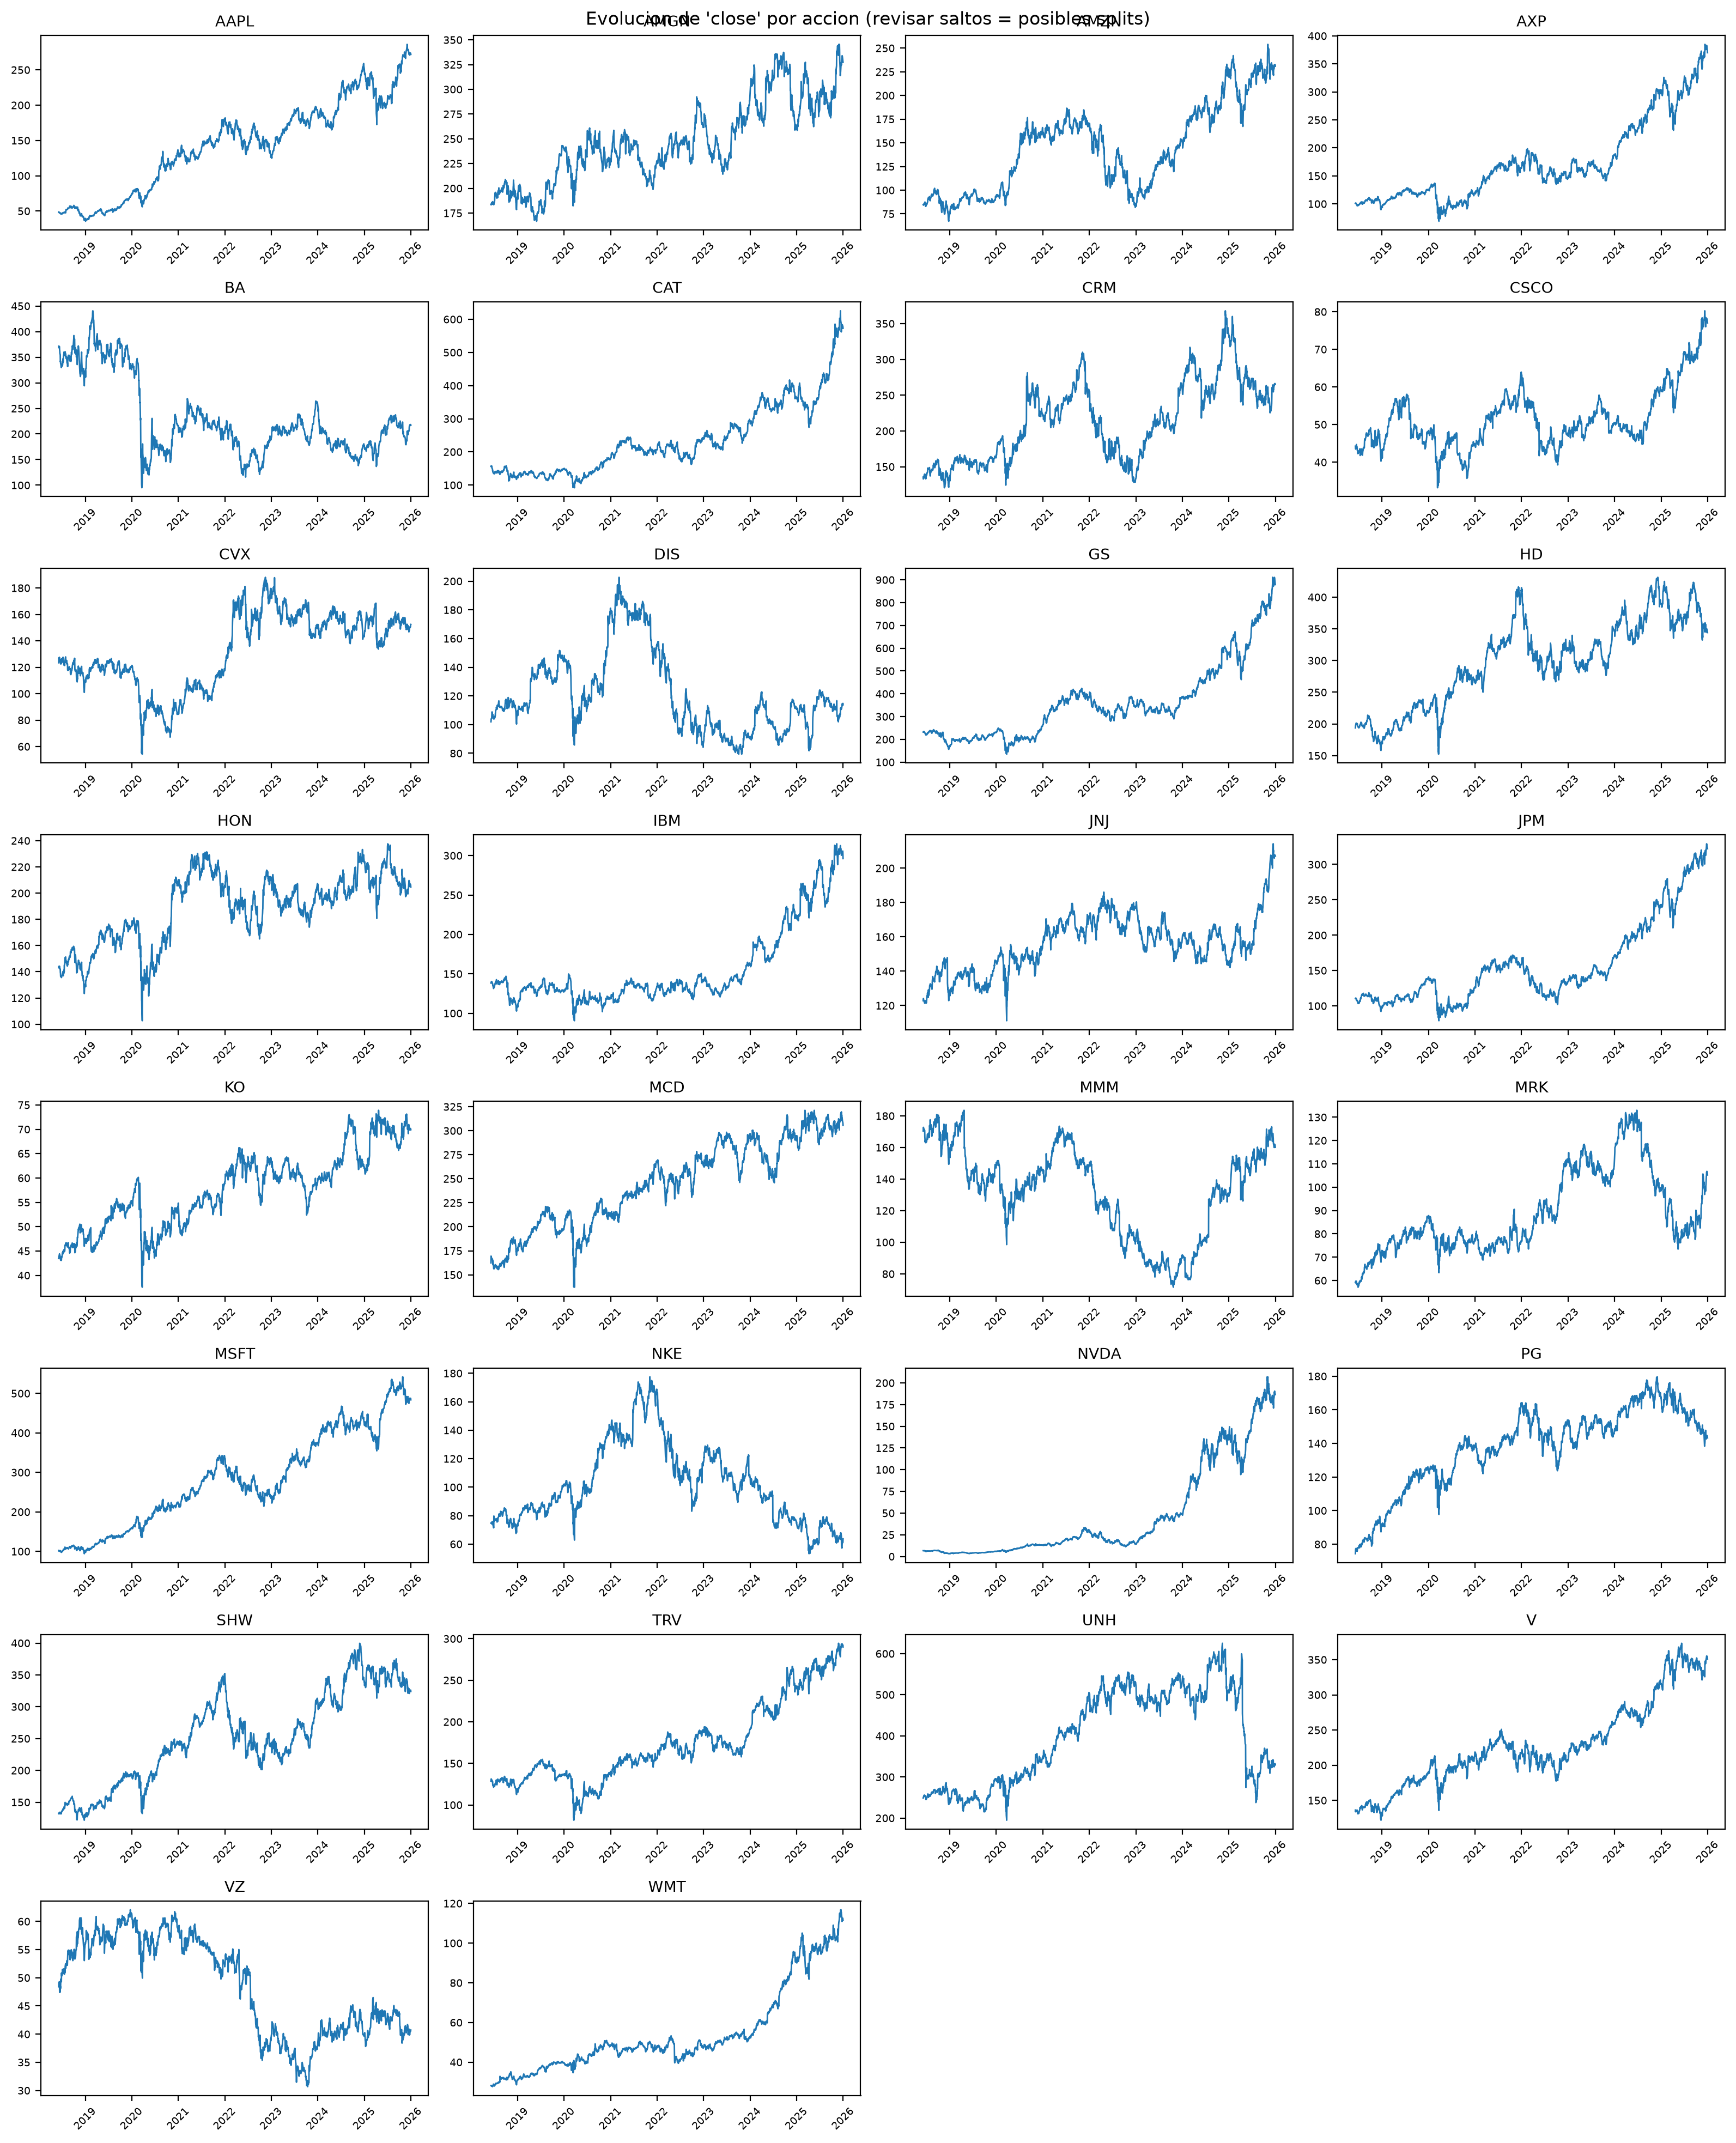

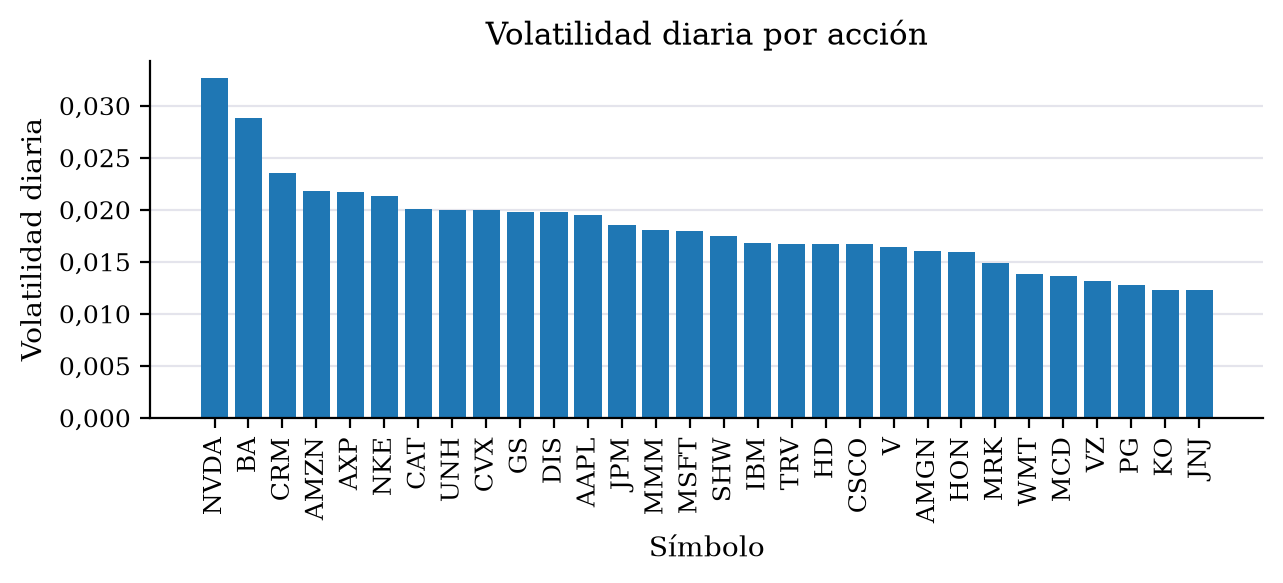

In [ ]:
# Estadisticos basicos y visualizacion rapida de las series

# -----------------------------------------------------------------------------
# 8.1 Retornos y volatilidad diaria (sobre el precio ajustado de Yahoo Finance)
# -----------------------------------------------------------------------------


def calcular_volatilidad_diaria(df, col_precio="adj_close"):
    """
    Calcula los retornos diarios porcentuales y la volatilidad (desviacion estandar)
    por cada simbolo sobre la columna de precio ajustado de Yahoo Finance.
    """
    df_temp = df.copy()

    # Asegurar el orden cronologico estricto por activo
    df_temp["date"] = pd.to_datetime(df_temp["date"])
    df_temp = df_temp.sort_values(["symbol", "date"]).reset_index(drop=True)

    # Retornos diarios porcentuales: (P_t - P_t-1) / P_t-1
    df_temp["retorno_diario"] = df_temp.groupby("symbol")[col_precio].pct_change()

    # Volatilidad (desviacion estandar de los retornos) por accion
    volatilidad = df_temp.groupby("symbol")["retorno_diario"].std()

    return df_temp, volatilidad.sort_values(ascending=False)


# Se usa 'adj_close', ya que Yahoo YA incluye los splits aplicados de forma retroactiva.
df_daily, volatilidad_diaria = calcular_volatilidad_diaria(df_daily, col_precio="adj_close")

plt.figure(figsize=(14, 4))
volatilidad_diaria.plot(kind="bar", color="#1f77b4", edgecolor="black")

plt.title("Volatilidad Diaria por Accion (Desviacion Estandar de Retornos)")
plt.xlabel("Simbolo")
plt.ylabel(r"Volatilidad Diaria ($\sigma$)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 8.2 Estadisticos descriptivos del precio de cierre
# -----------------------------------------------------------------------------

print(df_daily.groupby("symbol")["close"].describe())

# -----------------------------------------------------------------------------
# 8.3 Evolucion del precio de cierre, una grafica por accion
# -----------------------------------------------------------------------------


def plot_series_por_simbolo(df_daily, columna="close", ncols=4, figsize_por_grafico=(4, 2.5)):
    """Dibuja un grafico por simbolo (subplots en rejilla) para poder
    inspeccionar cada serie por separado y detectar saltos de precio
    (posibles splits) que en el grafico conjunto quedan ocultos."""
    simbolos = sorted(df_daily["symbol"].unique())
    n = len(simbolos)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_por_grafico[0] * ncols, figsize_por_grafico[1] * nrows),
        squeeze=False,
    )

    for i, symbol in enumerate(simbolos):
        ax = axes[i // ncols][i % ncols]
        g = df_daily[df_daily["symbol"] == symbol].sort_values("date")
        ax.plot(g["date"], g[columna], linewidth=1)
        ax.set_title(symbol, fontsize=10)
        ax.tick_params(axis="x", labelrotation=45, labelsize=7)
        ax.tick_params(axis="y", labelsize=7)

    # apagamos los huecos sobrantes de la rejilla si el numero de simbolos
    # no llena todas las celdas
    for j in range(n, nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")

    fig.suptitle(f"Evolucion de '{columna}' por accion (revisar saltos = posibles splits)", fontsize=12)
    plt.tight_layout()
    plt.show()


plot_series_por_simbolo(df_daily, columna="close")

# -----------------------------------------------------------------------------
# 8.4 Volatilidad diaria por accion (sobre el precio de cierre)

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 200,          # solo afecta a la vista en pantalla
})

# Coma decimal en el eje Y (como pide la guía)

retornos = df_daily.pivot(index="date", columns="symbol", values="close").pct_change()
volatilidad = retornos.std().sort_values(ascending=False)

ESTILO = {
    "font.family": "serif", "font.serif": ["Latin Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": 10,
    "axes.labelsize": 10, "axes.titlesize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E4E4EC",
    "axes.unicode_minus": True,
}
ANCHO_TEXTO = 6.3  # pulgadas (width=1.0\textwidth)

# Coma decimal y signo menos tipográfico en el eje y
coma = FuncFormatter(lambda v, _: f"{v:.3f}".replace(".", ",").replace("-", "−"))

COLOR = "#1f77b4"  # azul oscuro, igual que la figura de referencia

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(ANCHO_TEXTO, 2.8), layout="constrained")
    ax.bar(volatilidad.index, volatilidad.values, color=COLOR)
    ax.set_title("Volatilidad diaria por acción")
    ax.set_xlabel("Símbolo")
    ax.set_ylabel("Volatilidad diaria")
    ax.grid(axis="x", visible=False)           # solo rejilla horizontal
    ax.yaxis.set_major_formatter(coma)         # coma decimal en el eje y
    ax.tick_params(axis="x", labelrotation=90)

    plt.show()


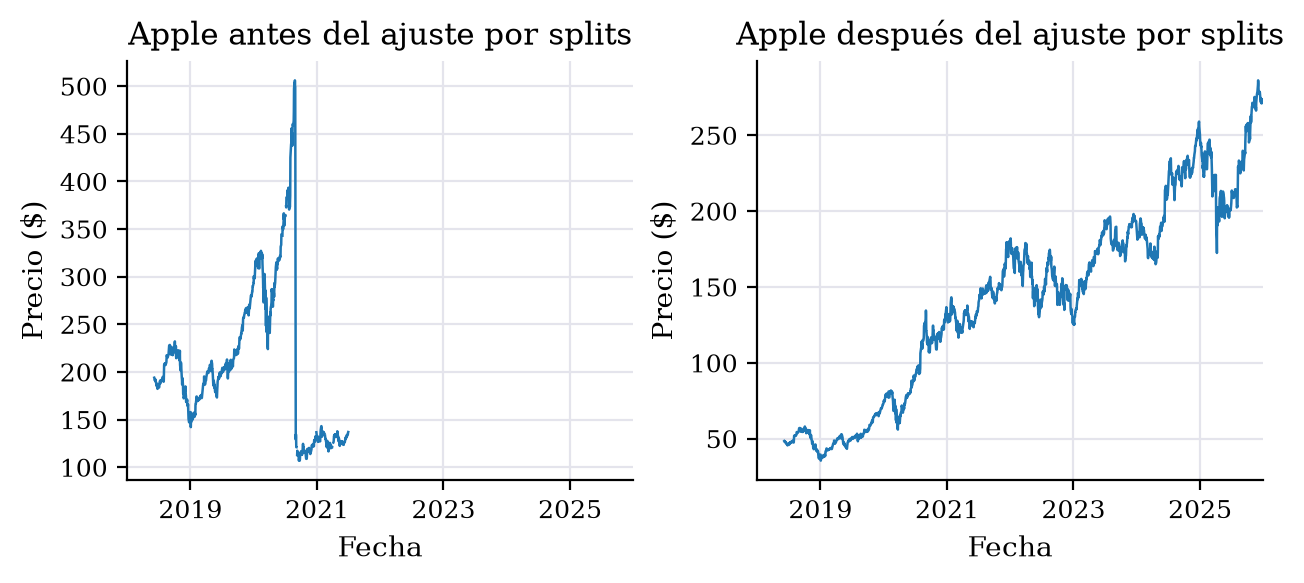

In [ ]:
# Comparación de Apple antes y después del ajuste por splits

apple_ajustada = df_daily[df_daily["symbol"] == "AAPL"].copy()

ESTILO = {
    "font.family": "serif", "font.serif": ["Latin Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": 10,
    "axes.labelsize": 10, "axes.titlesize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E4E4EC",
    "axes.unicode_minus": True,
}
ANCHO_TEXTO = 6.3  # pulgadas (width=1.0\textwidth)

# Coma decimal y signo menos tipográfico en los ejes
coma = FuncFormatter(lambda v, _: f"{v:.0f}".replace("-", "−"))

COLOR = "#1f77b4"  

fecha_inicio = pd.Timestamp("2018-01-01")
fecha_fin = pd.Timestamp("2026-01-01")
años = pd.to_datetime(["2019-01-01", "2021-01-01", "2023-01-01", "2025-01-01"])

with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_TEXTO, 2.8), layout="constrained")

    datos = [
        (df_daily_apple_original, "Apple antes del ajuste por splits"),
        (apple_ajustada,          "Apple después del ajuste por splits"),
    ]

    for ax, (df, titulo) in zip(axes, datos):
        ax.plot(df["date"], df["close"], color=COLOR, lw=0.9)
        ax.set_title(titulo)
        ax.set_xlabel("Fecha")
        ax.set_ylabel("Precio ($)")
        ax.yaxis.set_major_locator(MultipleLocator(50))
        ax.yaxis.set_major_formatter(coma)
        ax.set_xlim(fecha_inicio, fecha_fin)
        ax.set_xticks(años)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    plt.show()

## 9. Guardado Del Dataset Limpio

In [11]:
# Guardamos el resultado en un unico csv para que el resto de scripts del
# proyecto (seleccion de cartera, generacion de datos sinteticos...) partan de
# aqui, sin repetir la limpieza. La carpeta de datos no se sube al repositorio
# (indicado en las instrucciones de entrega), asi que el csv se guarda localmente.
# La columna `last` se omite porque es identica a `close`.

cols_finales = ["date", "symbol", "open", "high", "low", "close", "adj_close",
                "volume", "retorno_diario", "dias_entre_observaciones"]
df_guardar = df_daily[cols_finales].copy()

RUTA_SALIDA = os.path.join("Datos", "dowjones_limpio.csv")
df_guardar.to_csv(RUTA_SALIDA, index=False)
print("Guardado en:", RUTA_SALIDA)
print("Columnas guardadas:", df_guardar.columns.tolist())


Guardado en: Datos\dowjones_limpio.csv
Columnas guardadas: ['date', 'symbol', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'retorno_diario', 'dias_entre_observaciones']
